In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

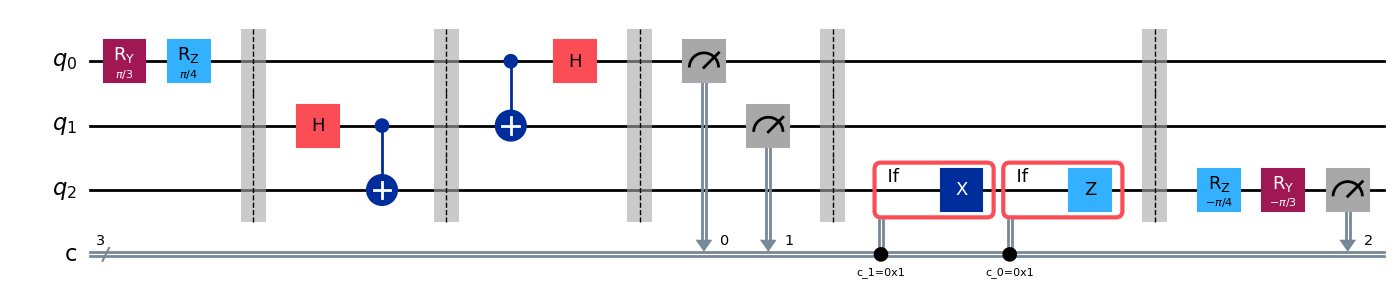

In [3]:
# Angles used to prepare the input state
theta = np.pi / 3
phi = np.pi / 4

# Three qubits and three classical bits:
# c[0], c[1] store Alice's measurements; c[2] stores verification
qc = QuantumCircuit(3, 3)

# Step 1: Prepare the state to teleport on qubit 0
qc.ry(theta, 0)
qc.rz(phi, 0)
qc.barrier()

# Step 2: Create an entangled Bell pair between Alice (qubit 1) and Bob (qubit 2)
qc.h(1)
qc.cx(1, 2)
qc.barrier()

# Step 3: Alice performs the Bell-measurement operations
qc.cx(0, 1)
qc.h(0)
qc.barrier()

# Step 4: Alice measures qubits 0 and 1
qc.measure(0, 0)
qc.measure(1, 1)
qc.barrier()

# Step 5: Bob corrects his qubit using Alice's classical measurement results
with qc.if_test((qc.clbits[1], 1)):
    qc.x(2)

with qc.if_test((qc.clbits[0], 1)):
    qc.z(2)

qc.barrier()

# Step 6: Verify the teleported state.
# Undo the original preparation on Bob's qubit.
qc.rz(-phi, 2)
qc.ry(-theta, 2)
qc.measure(2, 2)

qc.draw(output="mpl")

In [4]:
simulator = AerSimulator()
compiled_qc = transpile(qc, simulator)

result = simulator.run(compiled_qc, shots=1000).result()
counts = result.get_counts()

print("Measurement results:", counts)

Measurement results: {'010': 254, '000': 243, '001': 235, '011': 268}


In [7]:
plot_histogram(counts)
plt.show()

In [6]:
total_shots = sum(counts.values())
verification_ones = sum(count for bitstring, count in counts.items()
                         if bitstring.replace(" ", "")[0] == "1")
verification_zeros = total_shots - verification_ones

print("Total shots:", total_shots)
print("Verification results equal to 0:", verification_zeros)
print("Verification results equal to 1:", verification_ones)

if verification_ones == 0:
    print("Conclusion: Quantum teleportation was successful in this ideal simulation.")
else:
    print("Some verification results were 1. Check the circuit or simulator settings.")

Total shots: 1000
Verification results equal to 0: 1000
Verification results equal to 1: 0
Conclusion: Quantum teleportation was successful in this ideal simulation.


## Conclusion
The experiment demonstrates quantum teleportation using entanglement, measurement, classical communication, and correction gates. The state is transferred to Bob's qubit; the original state is not copied, and classical communication is still required.